In [3]:
import yaml
import warnings
import sys

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
# matplotlib.rcParams['font.family'] = 'Arial'

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
sys.path.append('../utils')
from utils import annotate_essentiality

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']

- Check if there is any correlation between copy number of a target and it's lfc
- Probably, lfc is affected by expression and expression is affected by copy number, how do I account for this during testing?
- Compare to Cas9 data with and without correction
- TODO: I guess I should only test on non-essential genes?

## Define data

The data objects should include:
- the actual data (lfc)
- copy number
- gene expression
- essentiality

Datasets I could use to test CNE:
- Cas9 data (Brunello)
- DepMap uncorrected Cas9 scores
- DepMap shRNA data
- our own data

In [5]:
cell_line = 'A549'  # H1299 most polyploid cell line, but p53-null. A549 is p53wt.

# Prepare CN annotations
depmap_data = pd.read_csv("/scratch/peidli/DepMap/Release_2024Q2/4lines_SYMPHONY_DepMap_2024Q2.csv", index_col=1)
depmap_data.index = depmap_data.index.str.replace("NCI", "")
depmap_cn = depmap_data.copy()
depmap_cn = depmap_cn.loc[:, (~depmap_cn.isna()).sum(0) != 0]  # remove all-nan columns
depmap_cn.index = depmap_cn.index.str.replace("NCI", "")
depmap_cn = depmap_cn.loc[:, depmap_cn.columns.str.startswith("Copy Number (Absolute)")]
depmap_cn.columns = depmap_cn.columns.str.split(') ', regex=False).str[1]
depmap_data.head()

,depmap_id,lineage_1,lineage_2,lineage_3,lineage_5,lineage_6,lineage_4,Copy Number (Absolute) A1BG,Copy Number (Absolute) NAT2,Copy Number (Absolute) ADA,...,"RNAi (Achilles+DRIVE+Marcotte, DEMETER2) RCE1","RNAi (Achilles+DRIVE+Marcotte, DEMETER2) HNRNPDL","RNAi (Achilles+DRIVE+Marcotte, DEMETER2) DMTF1","RNAi (Achilles+DRIVE+Marcotte, DEMETER2) PPP4R1","RNAi (Achilles+DRIVE+Marcotte, DEMETER2) CDH1","RNAi (Achilles+DRIVE+Marcotte, DEMETER2) SLC12A6","RNAi (Achilles+DRIVE+Marcotte, DEMETER2) KCNE2","RNAi (Achilles+DRIVE+Marcotte, DEMETER2) DGCR2","RNAi (Achilles+DRIVE+Marcotte, DEMETER2) CASP8AP2","RNAi (Achilles+DRIVE+Marcotte, DEMETER2) SCO2"
cell_line_display_name,,,,,,,,,,,,,,,,,,,,,
A549,ACH-000681,Lung,Non-Small Cell Lung Cancer,Lung Adenocarcinoma,NSCLC Adenocarcinoma,NaN,NaN,4.0,3.0,3.0,...,-0.175998,-0.131164,-0.010186,-0.122771,-0.174226,0.041545,0.034408,0.046675,-0.494911,0.291193
H1299,ACH-000510,Lung,Non-Small Cell Lung Cancer,Large Cell Lung Carcinoma,NSCLC Large Cell,NaN,NaN,2.0,2.0,3.0,...,0.007673,-0.079813,-0.144675,-0.168001,-0.065485,0.050484,0.012473,0.118726,-0.449712,0.148502
H1975,ACH-000587,Lung,Non-Small Cell Lung Cancer,Lung Adenocarcinoma,NSCLC Adenocarcinoma,NaN,NaN,5.0,2.0,4.0,...,-0.002248,-0.397568,0.170357,0.057002,-0.046726,0.362949,0.099721,-0.568136,-0.846634,-0.313744
HT29,ACH-000552,Bowel,Colorectal Adenocarcinoma,Colon Adenocarcinoma,NaN,NaN,NaN,4.0,1.0,4.0,...,-0.079875,-0.083020,0.063059,-0.124807,-0.201434,0.067224,-0.084018,-0.057337,-0.720760,-0.047736


In [8]:
# Load our Data
counts = pd.read_csv(Path(config['DATADIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
sample_names = np.sort(counts.columns[12:])
sample_names_wo_pools = np.sort(counts.columns[15:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in counts.index if 'control' in x.lower()]

# annotate essential genes
counts['essential'] = annotate_essentiality(counts.Gene)

# Normalize to NT depth
norm_factor = counts.loc[controls, pools].mean(axis=1).mean() / counts.loc[controls, sample_names].mean(axis=0)
ndf = counts.loc[:, sample_names] * norm_factor

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None
cell_line_cols = pd.Series({x: int(x.split('-')[1]) if 'pool' not in x else 'pool' for x in sample_names}).replace(cell_line_dict)
l2fc = l2fc.loc[:, (cell_line_cols==cell_line) & (l2fc.columns.str.contains('TP6'))]  # subset to cell line and TP6
l2fc['Gene'] = counts['Gene']
l2fc['essential'] = counts['essential']

# Add depmap copy number data
depmap_cn = depmap_data.copy()
depmap_cn = depmap_cn.loc[:, (~depmap_cn.isna()).sum(0) != 0]  # remove all-nan columns
depmap_cn.index = depmap_cn.index.str.replace("NCI", "")
depmap_cn = depmap_cn.loc[:, depmap_cn.columns.str.startswith("Copy Number (Absolute)")]
depmap_cn.columns = depmap_cn.columns.str.split(') ', regex=False).str[1]
df_sym = pd.merge(l2fc, depmap_cn.loc[cell_line], left_on='Gene', right_index=True, how='left').rename(columns={cell_line: 'depmap_cn'})
df_sym['avgFC'] = df_sym.loc[:, df_sym.columns.isin(sample_names_wo_pools)].mean(axis=1, skipna=True)

# Add GEX data from depmap
expression = depmap_data.loc[cell_line, depmap_data.columns.str.startswith("Expression Public 24Q2")]
expression.index = expression.index.str.replace("Expression Public 24Q2 ", "")
df_sym = pd.merge(df_sym, expression, left_on='Gene', right_index=True, how='left').rename(columns={cell_line: 'depmap_expression'})

df_sym.to_csv(Path(config['DATADIR']) / 'pooled_screen_1/LM_data_symphony_101.csv')

df_sym.head()

,sym-03-01-TP6,sym-03-02-TP6,sym-03-03-TP6,Gene,essential,depmap_cn,avgFC,depmap_expression
unique_guide_name,,,,,,,,
AATBC_ENST00000400385_1005,0.131893,0.115107,0.145292,AATBC,unknown,2.0,0.130764,NaN
AATBC_ENST00000400385_1562,0.247176,0.270797,0.307524,AATBC,unknown,2.0,0.275166,NaN
AATBC_ENST00000400385_1938,0.195283,0.296882,0.347489,AATBC,unknown,2.0,0.279885,NaN
AATBC_ENST00000400385_2713,0.023267,-0.124303,0.073560,AATBC,unknown,2.0,-0.009159,NaN
AATBC_ENST00000400385_28,0.097635,0.150209,0.182872,AATBC,unknown,2.0,0.143572,NaN


In [10]:
# DepMap Uncorrected scores
unc_df = pd.read_csv('/scratch/peidli/DepMap/CRISPRGeneEffectUncorrected.csv', index_col=0)
inv_map = {v: k for k, v in depmap_data.depmap_id.to_dict().items()}
unc_df.index = unc_df.index.map(inv_map)
unc_df = unc_df.loc[depmap_data.index]  # take only our cell lines
unc_df.columns = unc_df.columns.str.split(' (', regex=False).str[0]
unc_df = unc_df.loc[cell_line, :].T
unc_df = unc_df.to_frame().rename(columns={cell_line: 'uncorrected_score'})
unc_df['essential'] = annotate_essentiality(unc_df.index)

# Add depmap copy number data
unc_df = pd.merge(unc_df, depmap_cn.loc[cell_line], left_index=True, right_index=True, how='left').rename(columns={cell_line: 'depmap_cn'})

# Add GEX data from depmap
expression = depmap_data.loc[cell_line, depmap_data.columns.str.startswith("Expression Public 24Q2")]
expression.index = expression.index.str.replace("Expression Public 24Q2 ", "")
unc_df = pd.merge(unc_df, expression, left_index=True, right_index=True, how='left').rename(columns={cell_line: 'depmap_expression'})

unc_df.to_csv(Path(config['DATADIR']) / 'pooled_screen_1/LM_data_depmap.csv')

unc_df.head()

,uncorrected_score,essential,depmap_cn,depmap_expression
A1BG,-0.136163,unknown,4.0,2.440952
A1CF,0.138486,unknown,3.0,0.163499
A2M,0.133318,unknown,4.0,0.0
A2ML1,0.162955,unknown,4.0,0.028569
A3GALT2,0.219017,unknown,NaN,0.0


In [11]:
# DepMap siRNA scores
rnai_1 = depmap_data.columns.str.startswith("RNAi (Achilles+DRIVE+Marcotte, DEMETER2)")
rnai_df = depmap_data.loc[cell_line, rnai_1].T
rnai_df = rnai_df.to_frame().rename(columns={cell_line: 'rnai_score'})
rnai_df.index = rnai_df.index.str.replace('RNAi (Achilles+DRIVE+Marcotte, DEMETER2) ', '', regex=False)
rnai_df['essential'] = annotate_essentiality(rnai_df.index)

# Add depmap copy number data
rnai_df = pd.merge(rnai_df, depmap_cn.loc[cell_line], left_index=True, right_index=True, how='left').rename(columns={cell_line: 'depmap_cn'})
rnai_df.head()

# Add GEX data from depmap
expression = depmap_data.loc[cell_line, depmap_data.columns.str.startswith("Expression Public 24Q2")]
expression.index = expression.index.str.replace("Expression Public 24Q2 ", "")
rnai_df = pd.merge(rnai_df, expression, left_index=True, right_index=True, how='left').rename(columns={cell_line: 'depmap_expression'})

rnai_df.to_csv(Path(config['DATADIR']) / 'pooled_screen_1/LM_data_depmap_rnai.csv')

# # DepMap siRNA l2fc instead. Maybe they correct the score somehow
# # DepMap stopped releasing Achilles l2fc after Public Release 22Q2
# # https://figshare.com/ndownloader/files/34989955 -O Achilles_logfold_change.csv
# rnai_raw_df = pd.read_csv('/scratch/peidli/DepMap/Release_2022Q2/Achilles_logfold_change.csv', index_col=0)
# H1299_names = [x for x in rnai_raw_df.columns if 'H1299' in x]  # sample names are super weird
# rnai_raw_df = rnai_raw_df.loc[:, H1299_names]
# # We also need the guide-to-target mapping
# # wget https://figshare.com/ndownloader/files/34989880 -O Achilles_guide_map.csv
# achilles_guide_map = pd.read_csv('/scratch/peidli/DepMap/Release_2022Q2/Achilles_guide_map.csv', index_col=0)
# achilles_guide_map = achilles_guide_map[~achilles_guide_map.index.duplicated(keep=False)].copy()
# intersection = np.intersect1d(achilles_guide_map.index, rnai_raw_df.index)
# assert len(intersection) > 10000
# rnai_raw_df = rnai_raw_df.loc[intersection]
# rnai_raw_df.index = achilles_guide_map.loc[intersection, 'gene']
# rnai_raw_df.index = rnai_raw_df.index.str.split(' (', regex=False).str[0]
# rnai_raw_df['essential'] = annotate_essentiality(rnai_raw_df.index)
# # Add depmap copy number data
# rnai_raw_df = pd.merge(rnai_raw_df, depmap_cn.loc[cell_line], left_index=True, right_index=True, how='left').rename(columns={cell_line: 'depmap_cn'})
# rnai_raw_df['avgFC'] = rnai_raw_df.loc[:, H1299_names].mean(axis=1)
# rnai_raw_df.head()


In [12]:
# Brunello et al. data
cell_line_brunello = 'HT29'
normalization_method = 'all'  # 'NT'
# Normalize to NT depth gives really strange results and heavily unbalanced data
# Maybe the results of heave off-target effects? We end up with way more NT counts
# than I would naively expect. I will use the 'all' method for now.

# OP: https://doi.org/10.1038/s41467-018-07901-8
# https://github.com/francescojm/CRISPRcleanR/blob/master/inst/extdata/HT29-Brunello_counts.tsv
brunello_counts = pd.read_csv('../resources/public_data/HT29-Brunello_counts.tsv', index_col=0, sep='\t')
sample_names = ['Brunello_plasmid', 'Brunello_HT29-rep1', 'Brunello_HT29-rep2', 'Brunello_HT29-rep3']
sample_names_wo_pools = ['Brunello_HT29-rep1', 'Brunello_HT29-rep2', 'Brunello_HT29-rep3']
controls = brunello_counts.index.str.contains('Control')
pools = ['Brunello_plasmid']

if normalization_method == 'NT':
    # Normalize to NT depth
    norm_factor = brunello_counts.loc[controls, pools].mean(axis=1).mean() / brunello_counts.loc[controls, sample_names].mean(axis=0)
elif normalization_method == 'all':
    # Normalize to all guide depth
    norm_factor = brunello_counts.loc[:, pools].mean(axis=1).mean() / brunello_counts.loc[:, sample_names].mean(axis=0)
else:
    raise ValueError("Normalization method not recognized")
ndf = brunello_counts.loc[:, sample_names] * norm_factor

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names_wo_pools].T / ndf.loc[:, pools].mean(axis=1)).T
brunello_df = np.log2(fc)
brunello_df[brunello_df==-np.infty] = None
brunello_df['Gene'] = brunello_counts['gene']
brunello_df['essential'] = annotate_essentiality(brunello_df.Gene)

# Add depmap copy number data
depmap_cn = depmap_data.copy()
depmap_cn = depmap_cn.loc[:, (~depmap_cn.isna()).sum(0) != 0]  # remove all-nan columns
depmap_cn.index = depmap_cn.index.str.replace("NCI", "")
depmap_cn = depmap_cn.loc[:, depmap_cn.columns.str.startswith("Copy Number (Absolute)")]
depmap_cn.columns = depmap_cn.columns.str.split(') ', regex=False).str[1]
brunello_df = pd.merge(brunello_df, depmap_cn.loc[cell_line_brunello], left_on='Gene', right_index=True, how='left').rename(columns={cell_line_brunello: 'depmap_cn'})

# Add GEX data from depmap
expression = depmap_data.loc[cell_line, depmap_data.columns.str.startswith("Expression Public 24Q2")]
expression.index = expression.index.str.replace("Expression Public 24Q2 ", "")
brunello_df = pd.merge(brunello_df, expression, left_on='Gene', right_index=True, how='left').rename(columns={cell_line: 'depmap_expression'})

brunello_df['avgFC'] = brunello_df.loc[:, brunello_df.columns.isin(sample_names_wo_pools)].mean(axis=1, skipna=True)
brunello_df.head()

,Brunello_HT29-rep1,Brunello_HT29-rep2,Brunello_HT29-rep3,Gene,essential,depmap_cn,depmap_expression,avgFC
sgRNA,,,,,,,,
A1BG_1,0.108331,-0.453604,-0.427651,A1BG,unknown,4.0,2.440952,-0.257641
A1BG_2,-0.437116,0.103967,-0.291663,A1BG,unknown,4.0,2.440952,-0.208270
A1BG_3,NaN,NaN,-0.476751,A1BG,unknown,4.0,2.440952,-0.476751
A1BG_4,0.777834,-0.134636,-0.270874,A1BG,unknown,4.0,2.440952,0.124108
A2M_5,0.096437,0.293194,0.020341,A2M,unknown,3.0,0.0,0.136657


In [13]:
ndf.sum(axis=0)  # normalized so same depth

Brunello_plasmid      31957307.0
Brunello_HT29-rep1    31957307.0
Brunello_HT29-rep2    31957307.0
Brunello_HT29-rep3    31957307.0
dtype: float64

In [14]:
ndf.loc[controls].sum(axis=0)  # this might be problematic though; I do not go for NT normalization because of this imbalance

Brunello_plasmid      749123.000000
Brunello_HT29-rep1    903210.411687
Brunello_HT29-rep2    909913.048581
Brunello_HT29-rep3    901342.208333
dtype: float64

## With absolute copy number data from DepMap

Instead of copy number segments, I should directly take the absolute CN from depmap.

### Plotting

In [28]:
def plot_cne(data, ykey, label, xkey='depmap_cn', verbose=False, axs=None, show=False):
    palette = {'essential': 'tab:red', 'non-essential': 'tab:blue', 'unknown': 'tab:gray'}
    data = data[data[xkey]>0].copy()  # remove lost genes since we can't measure them really
    
    with sns.axes_style('darkgrid'):
        axs = pl.subplots(1, 2, figsize=(6*2, 3))[1] if axs is None else axs
    ax = axs[0]
    sns.boxplot(data=data, x=xkey, y=ykey, hue='essential', palette=palette, showfliers=False, ax=ax)

    # add regression lines for each hue
    from scipy.stats import linregress
    results = {}
    for hue in data.essential.unique():
        x, y = data[data.essential == hue][xkey], data[data.essential == hue][ykey]
        mask = ~x.isna() & ~y.isna() & (y!=np.infty)
        res = linregress(x[mask].astype(float).values, y[mask].astype(float).values, alternative='less')
        slope, intercept, r_value, p_value, std_err = res
        
        # Calculate 95% confidence interval on slope and intercept:
        # Two-sided inverse Students t-distribution
        # p - probability, df - degrees of freedom
        from scipy.stats import t
        tinv = lambda p, df: abs(t.ppf(p/2, df))
        ts = tinv(0.05, len(x)-2)
        if hue=='non-essential' and verbose:
            print(f'{hue}: slope={slope:.3f}, intercept={intercept:.3f}, r_value={r_value:.3f}, p_value={p_value:.3f}, std_err={std_err:.3f}')
            print(f"slope (95%): {res.slope:.3f} +/- {ts*res.stderr:.3f}")
            print(f"intercept (95%): {res.intercept:.3f}"
                f" +/- {ts*res.intercept_stderr:.3f}")
        results[hue] = [slope, intercept, std_err, res.intercept_stderr, r_value, p_value]
    results = pd.DataFrame(results, index=['slope', 'intercept', 'slope_stderr', 'intercept_stderr', 'r_value', 'p_value']).T

    n_entries = data.groupby(xkey).size()
    ax.set_xticklabels([f'{x}\n({n})' for x, n in zip(n_entries.index, n_entries)])

    ax = axs[1]
    # plot means and regression lines
    for hue in data.essential.unique():
        means = data[(data.essential == hue) & (data[ykey]!=np.infty)].groupby(xkey).mean()
        ax.plot(means.index, means[ykey], 'o', label=hue, color=palette[hue])
        # plot regression line
        slope, intercept, *_ = results.loc[hue]
        x = np.linspace(means.index.min(), means.index.max(), 100)
        y = x * slope + intercept
        ax.plot(x, y, color=palette[hue], linestyle='--')

    n_entries = data.groupby(xkey).size()
    ax.set_xticks(n_entries.index)
    ax.set_xticklabels([f'{x}\n({n})' for x, n in zip(n_entries.index, n_entries)])
        
    for ax in axs:
        # Add number of entries to x-axis tick labels
        ax.legend(fontsize=8, title='Essential Gene', title_fontsize=8)
        ax.set_xlabel('Total Copy Number of Target')
        ax.set_ylabel(f"{ykey}\n{label}")
        ax.set_title(f'Correlation between {xkey} and {ykey}\nin {cell_line} across guides')
        ax.axhline(0, color='black', linewidth=1, zorder=-1)
    # pl.suptitle(label, fontsize=16, y=1.1)
    # pl.savefig(f'../results/copynumber/cnv_vs_lfc_{cell_line}_boxplots.pdf', bbox_inches='tight')
    if show: pl.show()
    return results

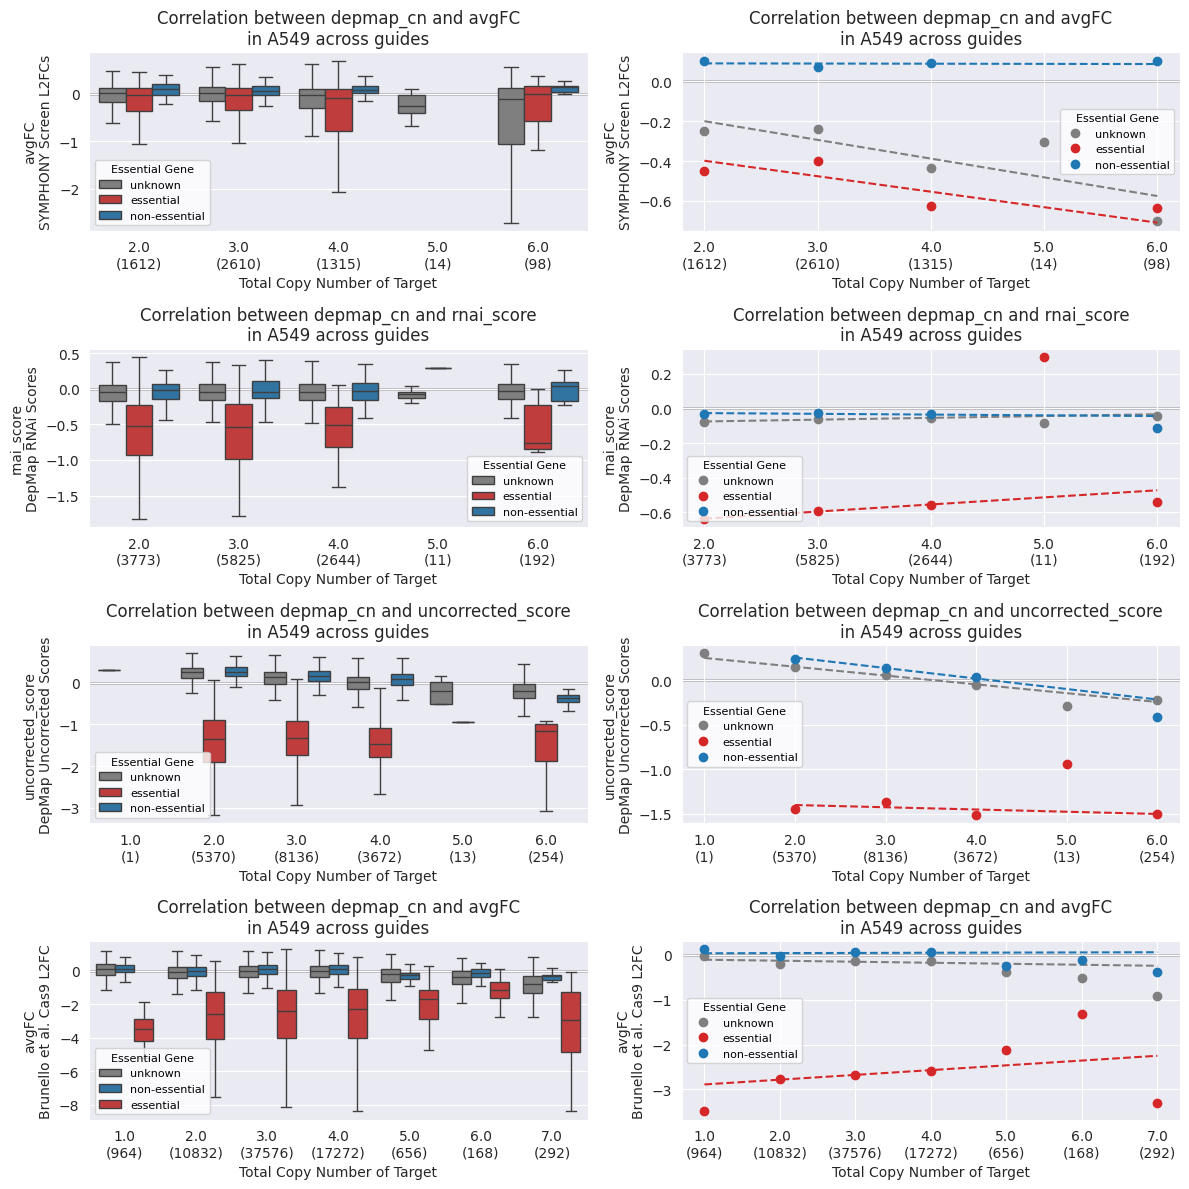

In [80]:
results = {}
with sns.axes_style('darkgrid'):
    fig, axss = pl.subplots(4, 2, figsize=(6*2, 3 * 4))
results['Symphony'] = plot_cne(df_sym, 'avgFC', "SYMPHONY Screen L2FCs", axs=axss[0])
results['RNAi'] = plot_cne(rnai_df, 'rnai_score', "DepMap RNAi Scores", axs=axss[1])
# results['RNAi_lfc'] = plot_cne(rnai_raw_df, 'avgFC', "DepMap RNAi L2FC")
results['DepMap'] = plot_cne(unc_df, 'uncorrected_score', "DepMap Uncorrected Scores", axs=axss[2])
results['Brunello'] = plot_cne(brunello_df, 'avgFC', "Brunello et al. Cas9 L2FC", axs=axss[3])
pl.tight_layout()
pl.savefig(f'../results/copynumber/cnv_vs_lfc_{cell_line}_boxplots.pdf', bbox_inches='tight')
pl.show()

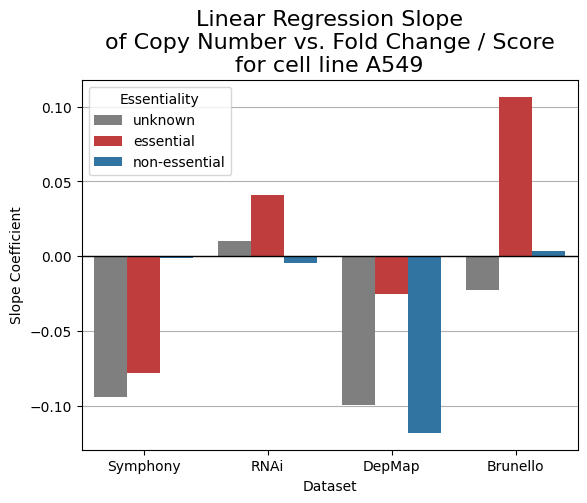

In [81]:
# Regression results per essentiality and dataset summarized in one plot
tab = pd.concat(results).reset_index().rename(columns={'level_0': 'Dataset', 'level_1': 'Essentiality'})
sns.barplot(data=tab, x='Dataset', y='slope', hue='Essentiality', zorder=2, palette = {'essential': 'tab:red', 'non-essential': 'tab:blue', 'unknown': 'tab:gray'})
pl.axhline(0, color='black', linewidth=1)
pl.title(f'Linear Regression Slope\nof Copy Number vs. Fold Change / Score\nfor cell line {cell_line}', fontsize=16)
pl.ylabel('Slope Coefficient')
pl.grid(axis='y', zorder=1)
pl.savefig(f'../results/copynumber/cnv_vs_lfc_{cell_line}_slopes.pdf', bbox_inches='tight')
pl.show()

In [31]:
# Let's look at expression data and see if we need to account for it

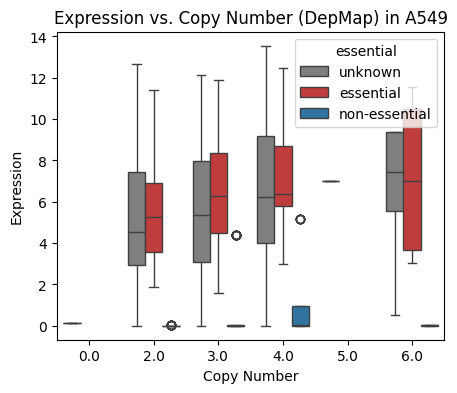

In [83]:
# There is a positive correlation between expression and copynumber that could influence 
# our regression between copynumber and foldchange. We should account for it.
fig, ax = pl.subplots(figsize=(5, 4))
sns.boxplot(data=df_sym, y='depmap_expression', x='depmap_cn', hue='essential', 
            palette = {'essential': 'tab:red', 'non-essential': 'tab:blue', 'unknown': 'tab:gray'}, ax=ax)
ax.set_xlabel('Copy Number')
ax.set_ylabel('Expression')
ax.set_title(f'Expression vs. Copy Number (DepMap) in {cell_line}')
pl.savefig(f'../results/copynumber/expression_vs_cnv_{cell_line}.pdf', bbox_inches='tight')
pl.show()

### Statistical Modelling

In [84]:
import time
from statsmodels.formula.api import mixedlm
from statsmodels.api import OLS, add_constant

#### OLS regression (averaging over replicates)

Simple OLS regression model:
$$L2FC=\beta_0 + \beta_1 C + \beta_2 E + \epsilon$$

Simple OLS regression model with interaction term:
$$L2FC=\beta_0 + \beta_1 C + \beta_2 E + \beta_3 (C\cdot E) + \epsilon$$

In [85]:
def OLS_regression(data, ykey, interaction=False, verbose=False):
    # prepare data
    data = data.copy()
    X = data[['depmap_cn', 'depmap_expression']]
    X = add_constant(X)
    if interaction:
        X['interaction'] = X['depmap_cn'] * X['depmap_expression']
    y = data[ykey]
    mask = ~X.isna().any(1) & ~y.isna()
    X = X[mask].values.astype(float)
    y = y[mask].values.astype(float)
    
    # Fit OLS model
    results = OLS(y, X).fit()
    if verbose:
        print(results.summary())
        
    results_dict = dict(
        coeff_expression=results.params[2],
        coeff_copynumber=results.params[1],
        intercept=results.params[0],
        r_value=results.rsquared,
        p_value_expression=results.pvalues[2],
        p_value_copynumber=results.pvalues[1],
        std_err=results.bse[1],
        aic=results.aic,
        bic=results.bic,
        log_likelihood=results.llf,
    )
    if interaction:
        results_dict['coeff_interaction'] = results.params[3]
        results_dict['p_value_interaction'] = results.pvalues[3]
    return results_dict

In [88]:
regression_results = {}
for name, ykey, data in [
    ('SYMPHONY', 'avgFC', df_sym), 
    ('DepMap', 'uncorrected_score', unc_df),
    ('RNAi', 'rnai_score', rnai_df),
    ]:
    regression_results[(name, 'OLS')] = OLS_regression(data, ykey, interaction=False, verbose=False)
    regression_results[(name, 'OLS_interaction')] = OLS_regression(data, ykey, interaction=True, verbose=False)
ols_regression_results = pd.DataFrame(regression_results)

In [90]:
ols_regression_results.to_csv("../results/copynumber/ols_regression_results.csv")
ols_regression_results.round(4)

SYMPHONY                      DepMap                  \
                            OLS OLS_interaction         OLS OLS_interaction   
coeff_expression        -0.1243         -0.0761     -0.0778         -0.1062   
coeff_copynumber         0.0010          0.0859     -0.0806         -0.1057   
intercept                0.3232          0.0690      0.4561          0.5311   
r_value                  0.1598          0.1619      0.1986          0.2002   
p_value_expression       0.0000          0.0000      0.0000          0.0000   
p_value_copynumber       0.9467          0.0030      0.0000          0.0000   
std_err                  0.0155          0.0289      0.0040          0.0058   
aic                  13088.3404      13078.3037  18976.7159      18943.4325   
bic                  13107.8148      13104.2696  18999.9592      18974.4236   
log_likelihood       -6541.1702      -6535.1519  -9485.3580      -9467.7163   
coeff_interaction           NaN         -0.0156         NaN          0.0093   
p_value_interaction         NaN          0.0005         NaN          0.0000   

                         RNAi                  
                          OLS OLS_interaction  
coeff_expression      -0.0282         -0.0358  
coeff_copynumber       0.0159          0.0089  
intercept             -0.0569         -0.0360  
r_value                0.0772          0.0776  
p_value_expression     0.0000          0.0000  
p_value_copynumber     0.0000          0.0282  
std_err                0.0028          0.0041  
aic                  414.6159        411.1457  
bic                  436.8257        440.7588  
log_likelihood      -204.3079       -201.5729  
coeff_interaction         NaN          0.0025  
p_value_interaction       NaN          0.0194

In [91]:
# Mediation analysis
def mediation_analysis(data, ykey, verbose=False):
    
    # Step 1: Effect of depmap_cn on lfc (total effect)
    X1 = add_constant(data[['depmap_cn']])
    y1 = data[ykey]
    mask1 = ~X1.isna().any(1) & ~y1.isna()
    model1 = OLS(y1[mask1].values.astype(float), X1[mask1].values.astype(float)).fit()

    # Step 2: Effect of depmap_cn on depmap_expression (a-path)
    X2 = add_constant(data[['depmap_cn']])
    y2 = data['depmap_expression']
    mask2 = ~X2.isna().any(1) & ~y2.isna()
    model2 = OLS(y2[mask2].values.astype(float), X2[mask2].values.astype(float)).fit()

    # Step 3: Effect of depmap_expression on lfc, while controlling for depmap_cn (b-path and direct effect c')
    X3 = add_constant(data[['depmap_cn', 'depmap_expression']])
    y3 = data[ykey]
    mask3 = ~X3.isna().any(1) & ~y3.isna()
    model3 = OLS(y3[mask3].values.astype(float), X3[mask3].values.astype(float)).fit()

    # Calculate indirect effect (a*b)
    a = model2.params[1]
    b = model3.params[2]
    indirect_effect = a * b

    # Direct effect (c')
    direct_effect = model3.params[1]

    # Total effect (c)
    total_effect = model1.params[1]
    if verbose:
        print(f"Indirect effect: {indirect_effect}")
        print(f"Direct effect: {direct_effect}")
        print(f"Total effect: {total_effect}")
    return dict(indirect_effect=indirect_effect, direct_effect=direct_effect, total_effect=total_effect)


In [92]:
med_ana_results = {}
med_ana_results["SYMPHONY"] = mediation_analysis(df_sym, 'avgFC', verbose=False);
med_ana_results["DepMap"] = mediation_analysis(unc_df, 'uncorrected_score', verbose=False);
med_ana_results["RNAi"] = mediation_analysis(rnai_df, 'rnai_score', verbose=False);
med_ana_df = pd.DataFrame(med_ana_results).T

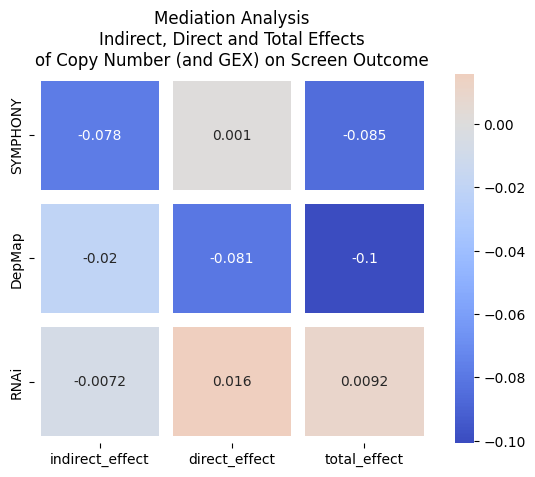

In [93]:
sns.heatmap(med_ana_df, annot=True, cmap='coolwarm', center=0, linewidths=10)
pl.title('Mediation Analysis\nIndirect, Direct and Total Effects\nof Copy Number (and GEX) on Screen Outcome')
pl.savefig(f'../results/copynumber/mediation_analysis_{cell_line}.pdf', bbox_inches='tight')
pl.show()

- The Durbin-Watson statistic (1.411) suggests some autocorrelation, which may need to be addressed.
- Conduct residual analysis to check for any patterns that might suggest model misspecification.
- Also do this analysis for the other cell lines.
- Currently I take average over replicates, can I include the replicates in the analysis somehow?

I think most of these issues can be addressed by using a proper model. I should probably try a mixed-effects model.

#### Mixed-effects model

In [94]:
# Convert to long format (different samples stacked on top of each other instead of multiple columns across samples)
df_sym['essential_codes'] = df_sym.essential.astype('category').cat.codes
df_sym['unique_guide_name'] = df_sym.index
df_long = df_sym.melt(id_vars=['unique_guide_name', 'Gene', 'essential', 'depmap_cn', 'depmap_expression', 'essential_codes'], 
                  value_vars=['sym-03-01-TP6', 'sym-03-02-TP6', 'sym-03-03-TP6'], 
                  var_name='replicate', value_name='logfold_change')
df_long = df_long[df_long.isna().sum(1)==0]

In [95]:
# Prepare data, ensure formats
data = df_long[df_long.essential!='unknown'].copy()
data.depmap_expression = data.depmap_expression.astype(float)
data.depmap_cn = data.depmap_cn.astype(int)
data.replicate = data.replicate.astype('category')

In [96]:
data.shape

(5247, 8)

- fixed effects:
    - copy number
    - gene expression
- random effects
    - Genes (I expect guides targeting different genes to have varying baseline lfc)
    - Replicates (The measurements are not independent for the same replicate)
- Technically I could also add target transcript as another random effect nested below genes, but I don't think it's necessary, given that the guides are not truly isoform-specific.

So how do I put this into python code?

Let's try writing down the model:
- Data:
    - $Y_{i}^{jk}$ is the lfc of the guide $i$ targeting gene $j$ in replicate $k$
    - $C^{j}$ is the copy number of gene $j$
    - $E^{j}$ is the gene expression of gene $j$
- Coefficients:
    - $\beta_{0}$ is the intercept (fixed effect); overall baseline lfc across all genes and replicates
    - $\beta_{1}$ is the coefficient for copy number (fixed effect); average change in lfc per unit change in copy number
    - $\beta_{2}$ is the coefficient for gene expression (fixed effect); average change in lfc per unit change in gene expression
    - $u_{j}\sim N(0,\sigma^2_u)$ is the random intercept for gene $j$
    - $v_{k}\sim N(0,\sigma^2_v)$ is the random intercept for replicate $k$
    - $\epsilon_{i}^{jk}\sim N(0,\sigma^2_\epsilon)$ is the residual error

The model is then:
$$Y_{i}^{jk} = \beta_{0} + \beta_{1}C^{j} + \beta_{2}E^{j} + u_{j} + v_{k} + \epsilon_{i}^{jk}$$

Open questions:
- I should probably also include the interaction between copy number and gene expression, right?
- There is no variation in copy number or expression for guides targeting the same gene, even across replicates, since we did not measure those per replicate (and copy number would be constant anyways). Should I still include genes as random effects?
    - Yes, still makes sense. Assume you have two genes with the same CN and GEX. The guides targeting these genes will still have different baseline lfc, which is what the gene random effect captures.

In [97]:
def mixed_effect_model(data, verbose=False):
    start_time = time.time()
    # Random intercept per gene to account for differences in baseline l2fc (e.g. by biological function)
    model = mixedlm("logfold_change ~ depmap_cn + depmap_expression", # fixed effects
                    data,
                    groups=data["Gene"], # random intercept per gene
                    # re_formula="~1|replicate"  # random intercept per replicate
                    )
    # Would be nice but not possible in python:
    # Random intercept per replicate to account for technical variability across replicates
    result = model.fit()
    if verbose:
        print(result.summary())
    print("--- %s seconds ---" % (time.time() - start_time))
    return result

In [98]:
result = mixed_effect_model(data, verbose=True)

            Mixed Linear Model Regression Results
Model:             MixedLM Dependent Variable: logfold_change
No. Observations:  5247    Method:             REML          
No. Groups:        223     Scale:              0.7240        
Min. group size:   12      Log-Likelihood:     -6825.3352    
Max. group size:   63      Converged:          Yes           
Mean group size:   23.5                                      
-------------------------------------------------------------
                  Coef.  Std.Err.    z    P>|z| [0.025 0.975]
-------------------------------------------------------------
Intercept          0.288    0.121   2.382 0.017  0.051  0.525
depmap_cn          0.028    0.036   0.778 0.436 -0.043  0.099
depmap_expression -0.135    0.010 -13.180 0.000 -0.155 -0.115
Group Var          0.197    0.026                            

--- 39.55483794212341 seconds ---


In [99]:
# residual analysis
def plot_model_eval(data, result, show=True):
    with sns.axes_style('darkgrid'):
        _, axs = pl.subplots(1, 3, figsize=(6*3, 6))
    
    results_tab = data.copy()
    results_tab['fitted'] = result.fittedvalues
    results_tab['residual'] = result.resid
    
    # Plot residuals against fitted values
    ax = axs[0]
    sns.scatterplot(data=results_tab, x='fitted', y='residual', 
                    size='depmap_cn',
                    hue='essential', ax=ax,
                    palette={'essential': 'tab:red', 'non-essential': 'tab:blue'}, 
                    alpha=0.5)
    # sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
    ax.axhline(0, color='red', linestyle='--')
    ax.set_xlabel('Fitted values (L2FC)')
    ax.set_ylabel('Residuals')
    ax.set_title('Mixed LM: Residuals vs Fitted Values')
    
    # I see that there is almost not effect from replicates, but strong effect from genes
    ax = axs[1]
    random_effects = pd.concat(result.random_effects).reset_index(level=1, drop=True)
    sns.histplot(random_effects, ax=ax)
    ax.set_xlabel('Random Effect per Gene')
    ax.set_title('Distribution of Random Effects per Gene')
    
    
    # QQ-plot of residuals
    ax = axs[2]
    from statsmodels.api import qqplot
    from scipy import stats
    qqplot(results_tab['residual'], line='45', dist=stats.distributions.norm, ax=ax)
    ax.set_title('Normal Q-Q Plot of Residuals')
    if show: pl.show()

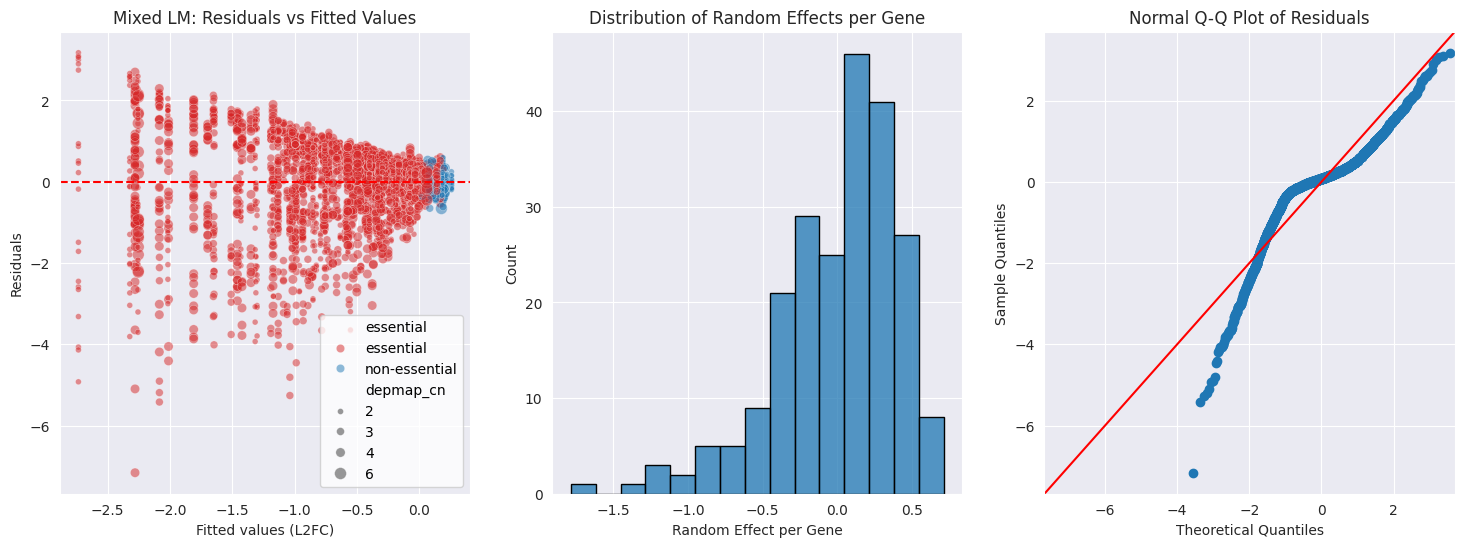

In [100]:
plot_model_eval(data, result, show=False)
pl.savefig(f'../results/copynumber/mixedlm_residuals_{cell_line}.pdf', bbox_inches='tight')
pl.show()

In [101]:
log_likelihood = result.llf  # Log-Likelihood
n_params = len(result.fe_params) + len(result.random_effects) + 1  # fixed + random effects + scale
n = len(data)

aic = 2 * n_params - 2 * log_likelihood
bic = np.log(n) * n_params - 2 * log_likelihood

print(f"AIC: {np.round(aic,0)}")
print(f"BIC: {np.round(bic,0)}")

AIC: 14105.0
BIC: 15595.0
